# Домашнее задание 8

Вам предстоит поработать с данными про отток клиентов банка и построить визуализации для них, отражающие те или иные закономерности.

Описание признаков:

* RowNumber - номер строки таблицы
* CustomerId - идентификатор клиента
* Surname - фамилия клиента
* CreditScore - кредитный рейтинг клиента (чем он выше, тем больше клиент брал кредитов и возвращал их)
* Geography - страна, из которой клиент (банк межнациональный)
* Gender - пол клиента
* Age - возраст клиента
* Tenure - сколько лет клиент пользуется банком
* Balance - сколько у клиента денег на счетах в банке
* NumOfProduct - число услуг банка, которые приобрел клиент
* HasCrCard - есть ли у клиента кредитная карта (1 - да, 0 - нет)
* IsActiveMember - есть ли у клиента статус активного участника банка (1 - да, 0 - нет)
* EstimatedSalary - предполагаемая заработная плата клиента
* Exited - статус ушедшего (1 - ушедший клиент, 0 - лояльный клиент)


In [1]:
import pandas as pd
churn_data = pd.read_csv('churn.csv')
churn_data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
churn_data.shape

(10000, 14)

## Задание 1

Визуализируйте распределение баланса пользователей. Попробуйте использовать хотя бы два типа графиков для этого. Подпишите оси и добавьте название графика. По желанию добавьте дополнительное оформление (например, поменяйте цвета или размер шрифта). 

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

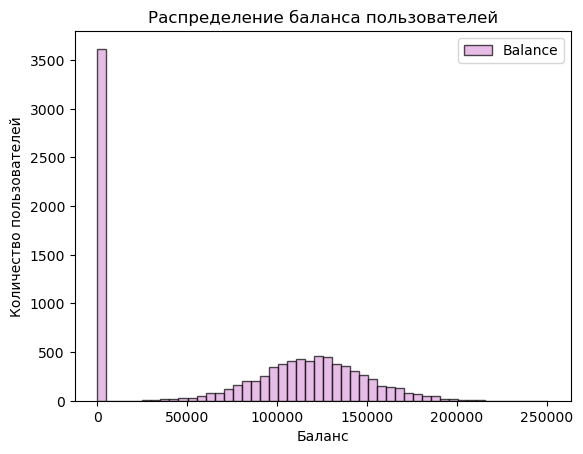

In [4]:
fig, ax = plt.subplots()

ax.hist(churn_data['Balance'], bins=50, color="plum", edgecolor="black", alpha=0.7, label="Balance")

ax.set_title("Распределение баланса пользователей")
ax.set_xlabel("Баланс")
ax.set_ylabel("Количество пользователей")

ax.legend()

plt.show()

In [25]:
sns.set_style('darkgrid')
sns.set_palette('dark')
sns.set(rc = {"figure.figsize": (6, 4), "figure.dpi" : 120})

**Распределение баланса в зависимости от пола клиента.**

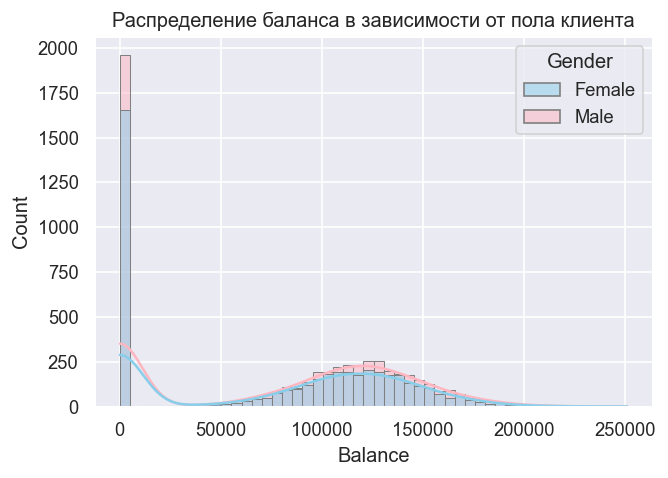

In [23]:
sns.histplot(
    x='Balance', 
    data=churn_data, 
    bins=50,
    kde=True,
    hue='Gender',                          
    palette=['skyblue', 'lightpink'], 
    edgecolor='grey'                  
)

plt.title('Распределение баланса в зависимости от пола клиента')
plt.show()

**Распределение баланса в зависимости от страны.**

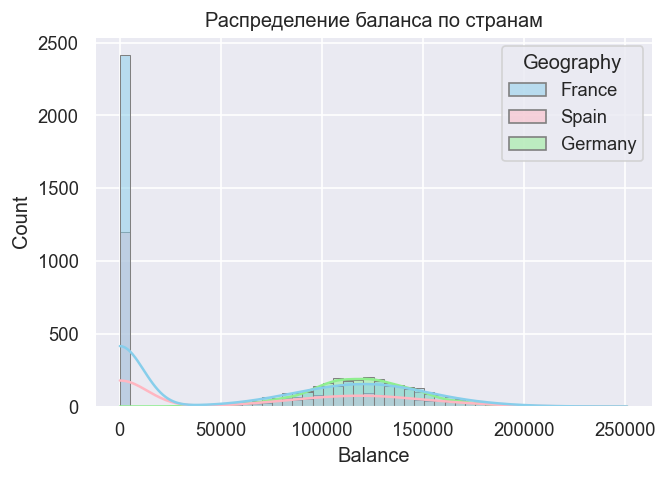

In [31]:
sns.histplot(
    x='Balance', 
    data=churn_data, 
    bins=50,
    kde=True,
    hue='Geography',                          
    palette=['skyblue', 'lightpink', 'lightgreen'], 
    edgecolor='grey'                  
)

plt.title('Распределение баланса по странам')
plt.show()

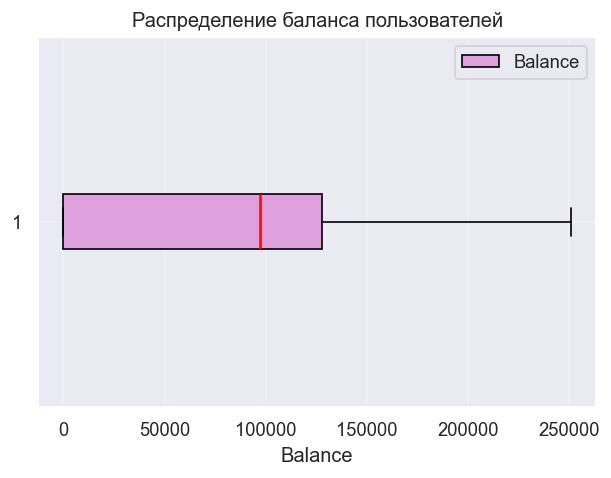

In [26]:
fig, ax = plt.subplots()

ax.boxplot(churn_data['Balance'], 
           vert=False, 
           patch_artist=True, 
           boxprops=dict(facecolor='plum'),
           medianprops=dict(color='red', linewidth=1.5),
           label="Balance")

ax.set_title("Распределение баланса пользователей")
ax.set_xlabel("Balance")
plt.grid(True, alpha=0.3)

ax.legend()

plt.show()

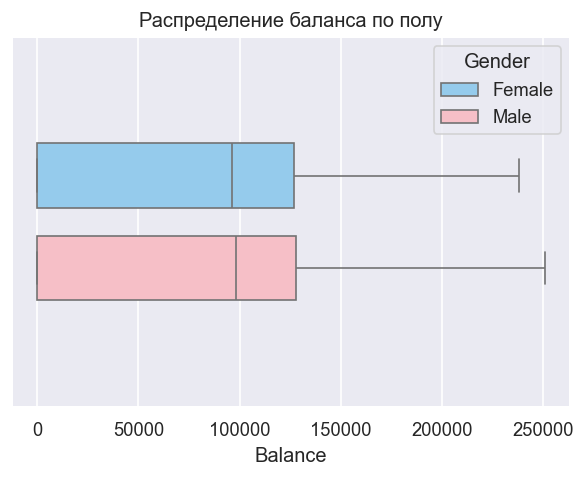

In [33]:
sns.boxplot(
    x='Balance',
    data=churn_data,
    width=0.5,
    hue='Gender',
    palette=['lightskyblue', 'lightpink'],
    gap=0.3
)

plt.title('Распределение баланса по полу');

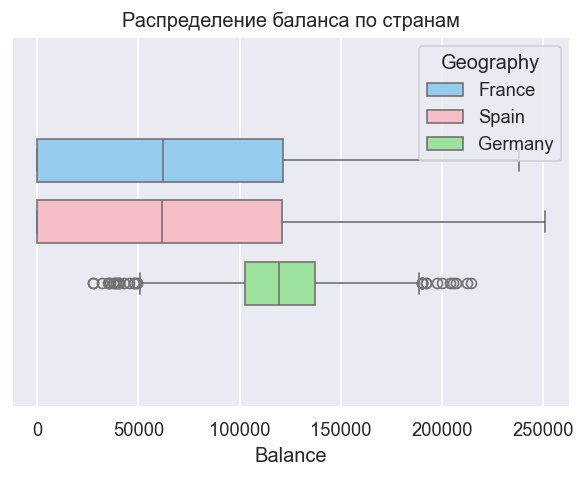

In [32]:
sns.boxplot(
    x='Balance',
    data=churn_data,
    width=0.5,
    hue='Geography',
    palette=['lightskyblue', 'lightpink', 'lightgreen'],
    gap=0.3
)

plt.title('Распределение баланса по странам');

## Задание 2

Постройте еще хотя бы 5 визуализаций на ваш вкус и проинтерпретируйте их.

**Количество пользователей в каждой стране с разделением по полу**

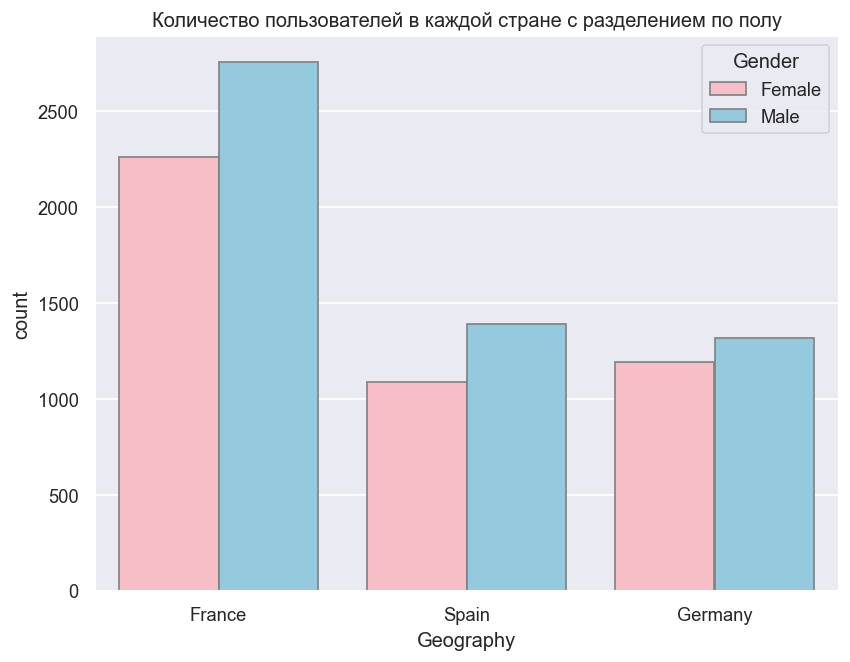

In [16]:
sns.countplot(
    data=churn_data, 
    x='Geography', 
    hue='Gender',
    palette=['lightpink', 'skyblue'], 
    edgecolor='grey'
)

plt.title('Количество пользователей в каждой стране с разделением по полу')
plt.show()

**Распределение возраста пользователей.**

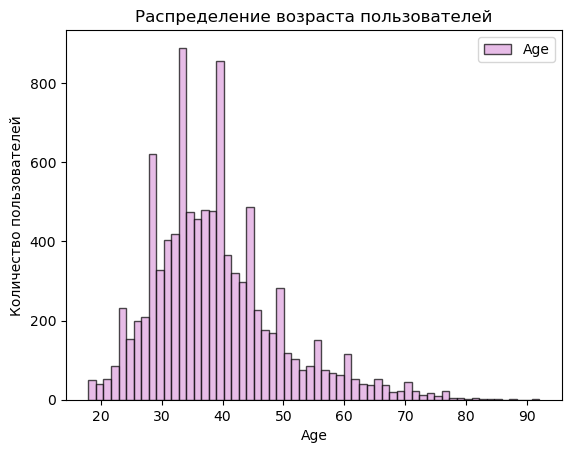

In [103]:
fig, ax = plt.subplots()

ax.hist(churn_data['Age'], bins=60, color="plum", edgecolor="black", alpha=0.7, label="Age")

ax.set_title("Распределение возраста пользователей")
ax.set_xlabel("Age")
ax.set_ylabel("Количество пользователей")

ax.legend()

plt.show()

**Распределение зарплаты пользователей.**

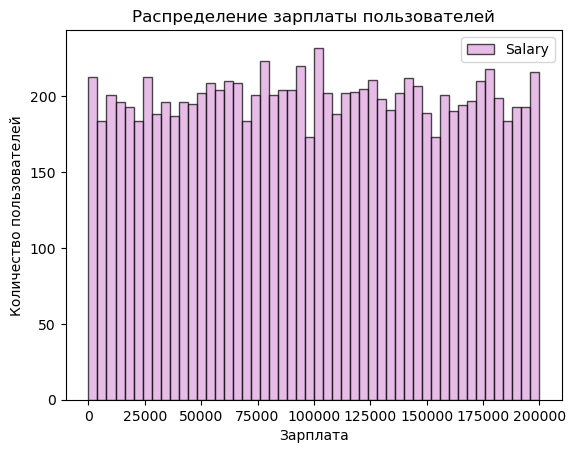

In [150]:
fig, ax = plt.subplots()

ax.hist(churn_data['EstimatedSalary'], bins=50, color="plum", edgecolor="black", alpha=0.7, label="Salary")

ax.set_title("Распределение зарплаты пользователей")
ax.set_xlabel("Зарплата")
ax.set_ylabel("Количество пользователей")

ax.legend()

plt.show()

**Количество клиентов в каждой стране.**

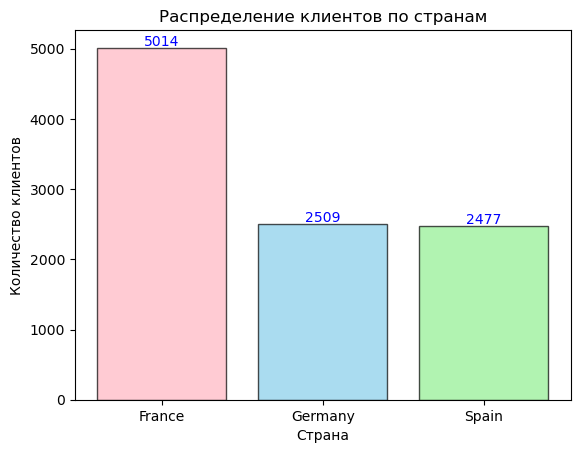

In [175]:
fig, ax = plt.subplots()

country_is_amount = churn_data.groupby('Geography').size()

ax.bar(country_is_amount.index, 
       country_is_amount.values, 
       color=["lightpink", "skyblue", "lightgreen"], 
       edgecolor="black", 
       alpha=0.7 
       )

for i, v in enumerate(country_is_amount.values):
    ax.text(i, v+22, str(country_is_amount.values[i]), color='blue', ha='center')

ax.set_title("Распределение клиентов по странам")
ax.set_xlabel("Страна")
ax.set_ylabel("Количество клиентов")

plt.show()

**Количество оттока клиентов в каждой стране.**

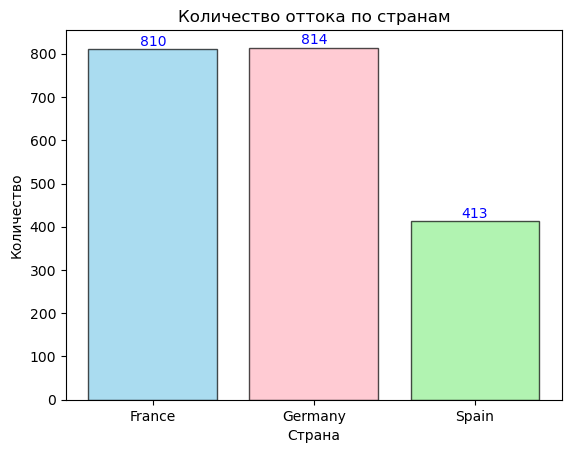

In [176]:
fig, ax = plt.subplots()

country_is_exited = churn_data.groupby('Geography')['Exited'].sum()

ax.bar(country_is_exited.index, 
       country_is_exited.values, 
       color=["skyblue", "lightpink", "lightgreen"], 
       edgecolor="black", 
       alpha=0.7
      )

for i, v in enumerate(country_is_exited.values):
    ax.text(i, v+8, str(country_is_exited.values[i]), color='blue', ha='center')

ax.set_title("Количество оттока по странам")
ax.set_xlabel("Страна")
ax.set_ylabel("Количество")

plt.show()

**Процент оттока клиентов по странам**

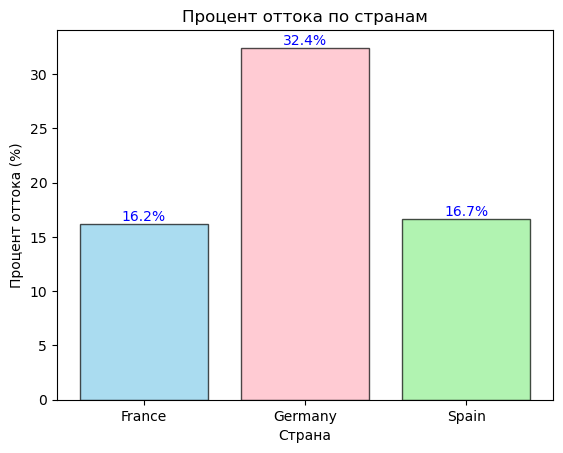

In [161]:
fig, ax = plt.subplots()

country_is_exited = churn_data.groupby('Geography')['Exited'].mean()*100

ax.bar(country_is_exited.index, 
       country_is_exited.values, 
       color=["skyblue", "lightpink", "lightgreen"], 
       edgecolor="black", 
       alpha=0.7
      )

for i, v in enumerate(country_is_exited.values):
    ax.text(i, v+0.3, str(round(float(country_is_exited.values[i]), 1))+'%', color='blue', ha='center')

ax.set_title("Процент оттока по странам")
ax.set_xlabel("Страна")
ax.set_ylabel("Процент оттока (%)")

plt.show()

**ГЕОГРАФИЧЕСКОЕ РАСПРЕДЕЛЕНИЕ И ОТТОК (на одном полотне).**

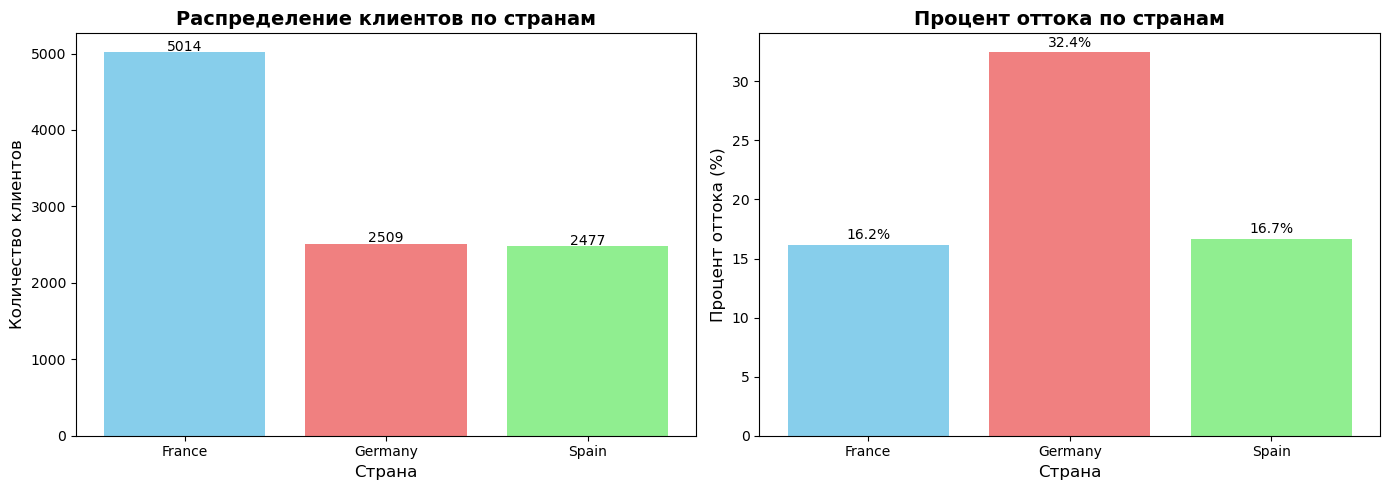

In [219]:
fig, axes = plt.subplots(
    1, 
    2, 
    figsize=(14, 5))

# Количество клиентов по странам
country_counts = churn_data['Geography'].value_counts()
axes[0].bar(country_counts.index, country_counts.values, 
           color=['skyblue', 'lightcoral', 'lightgreen'])
axes[0].set_xlabel('Страна', fontsize=12)
axes[0].set_ylabel('Количество клиентов', fontsize=12)
axes[0].set_title('Распределение клиентов по странам', fontsize=14, fontweight='bold')
for i, v in enumerate(country_counts.values):
    axes[0].text(i, v + 20, str(v), ha='center')

# Процент оттока по странам
country_churn = churn_data.groupby('Geography')['Exited'].mean() * 100
axes[1].bar(country_churn.index, country_churn.values,
           color=['skyblue', 'lightcoral', 'lightgreen'])
axes[1].set_xlabel('Страна', fontsize=12)
axes[1].set_ylabel('Процент оттока (%)', fontsize=12)
axes[1].set_title('Процент оттока по странам', fontsize=14, fontweight='bold')

for i, v in enumerate(country_churn.values):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center')

plt.tight_layout()
plt.show()

**Средний баланс на счету в зависимости от пола клиента.**

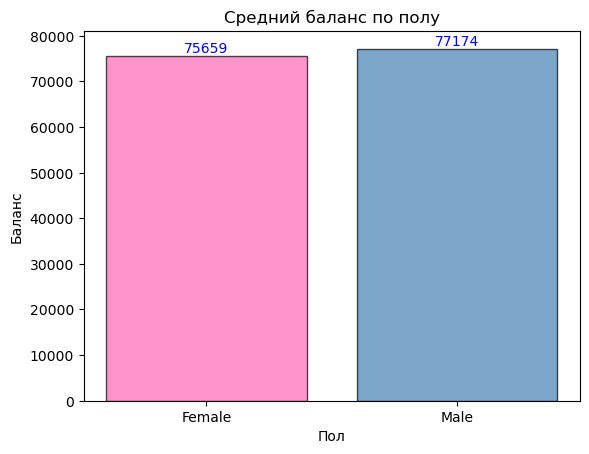

In [186]:
fig, ax = plt.subplots()

gender_balance = churn_data.groupby('Gender')['Balance'].mean()

ax.bar(gender_balance.index, 
       gender_balance.values, 
       color=["hotpink", "steelblue"], 
       edgecolor="black", 
       alpha=0.7
      )

for i, v in enumerate(gender_balance.values):
    ax.text(i, v+600, str(round(float(gender_balance.values[i]))), color='blue', ha='center')

ax.set_title("Средний баланс по полу")
ax.set_xlabel("Пол")
ax.set_ylabel("Баланс")

plt.show()

**Процент оттока в зависимости от пола клиента.**

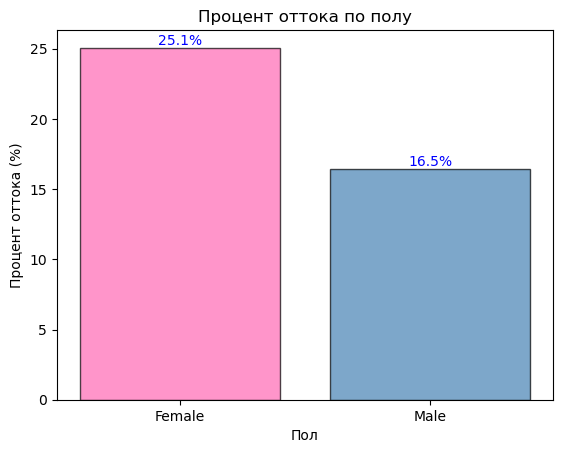

In [187]:
fig, ax = plt.subplots()

gender_is_exited = churn_data.groupby('Gender')['Exited'].mean()*100

ax.bar(gender_is_exited.index, 
       gender_is_exited.values, 
       color=["hotpink", "steelblue"], 
       edgecolor="black", 
       alpha=0.7 
       )

for i, v in enumerate(gender_is_exited.values):
    ax.text(i, v+0.2, str(round(float(gender_is_exited.values[i]), 1))+'%', color='blue', ha='center')

ax.set_title("Процент оттока по полу")
ax.set_xlabel("Пол")
ax.set_ylabel("Процент оттока (%)")

plt.show()

**Процент оттока по возрасту.**

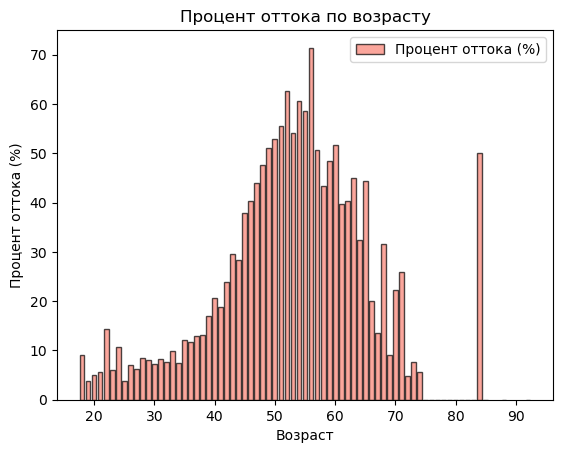

In [190]:
fig, ax = plt.subplots()

gender_is_exited = churn_data.groupby('Age')['Exited'].mean()*100

ax.bar(gender_is_exited.index, 
       gender_is_exited.values, 
       color=["salmon"], 
       edgecolor="black", 
       alpha=0.7, 
       label="Процент оттока (%)")

ax.set_title("Процент оттока по возрасту")
ax.set_xlabel("Возраст")
ax.set_ylabel("Процент оттока (%)")

ax.legend()

plt.show()

**Средний баланс клиента в зависимости от возраста**

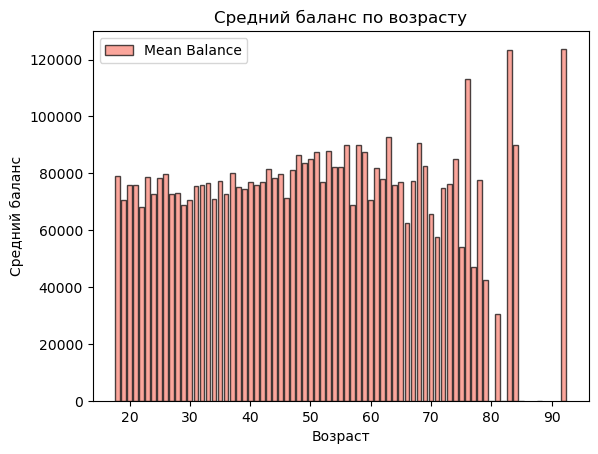

In [197]:
fig, ax = plt.subplots()

gender_is_exited = churn_data.groupby('Age')['Balance'].mean()

ax.bar(gender_is_exited.index, 
       gender_is_exited.values, 
       color=["salmon"], 
       edgecolor="black", 
       alpha=0.7, 
       label="Mean Balance")

ax.set_title("Средний баланс по возрасту")
ax.set_xlabel("Возраст")
ax.set_ylabel("Средний баланс")

ax.legend()

plt.show()

**Количество ушедших клиентов в зависимоти от возраста.**

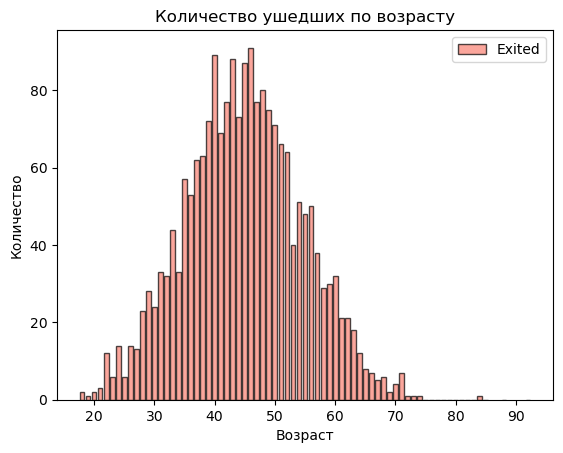

In [196]:
fig, ax = plt.subplots()

gender_is_exited = churn_data.groupby('Age')['Exited'].sum()

ax.bar(gender_is_exited.index, 
       gender_is_exited.values, 
       color=["salmon"], 
       edgecolor="black", 
       alpha=0.7, 
       label="Exited")

ax.set_title("Количество ушедших по возрасту")
ax.set_xlabel("Возраст")
ax.set_ylabel("Количество")

ax.legend()

plt.show()

**Распределение баланса по возрастам.**

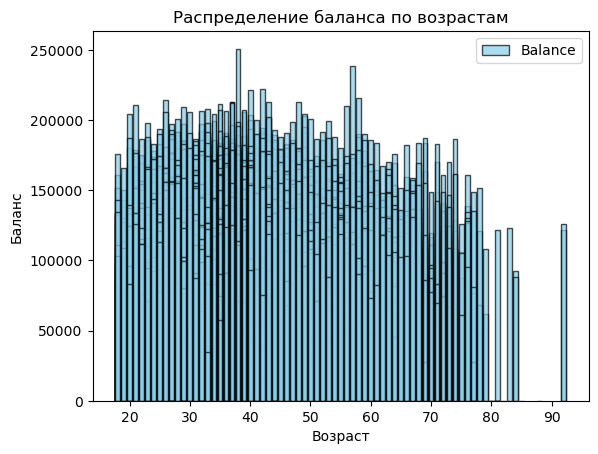

In [200]:
fig, ax = plt.subplots()

ax.bar(churn_data['Age'], 
       churn_data['Balance'], 
       color="skyblue", 
       edgecolor="black", 
       alpha=0.7, 
       label="Balance")

ax.set_title("Распределение баланса по возрастам")
ax.set_xlabel("Возраст")
ax.set_ylabel("Баланс")

ax.legend()

plt.show()

**Взаимосвязь между возрастом и балансом.**

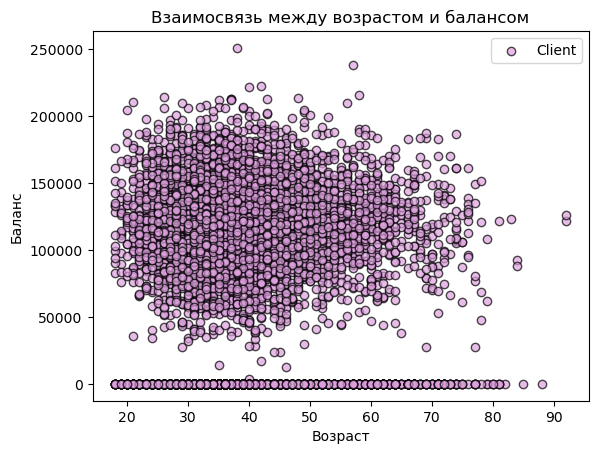

In [216]:
fig, ax = plt.subplots()

ax.scatter(
    churn_data['Age'], 
    churn_data['Balance'], 
    color="plum", 
    edgecolor="black", 
    alpha=0.7, 
    label="Client"
)

ax.set_title("Взаимосвязь между возрастом и балансом")
ax.set_xlabel("Возраст")
ax.set_ylabel("Баланс")

ax.legend()

plt.show()

**Взаимосвязь между кредитным рейтингом и балансом.**

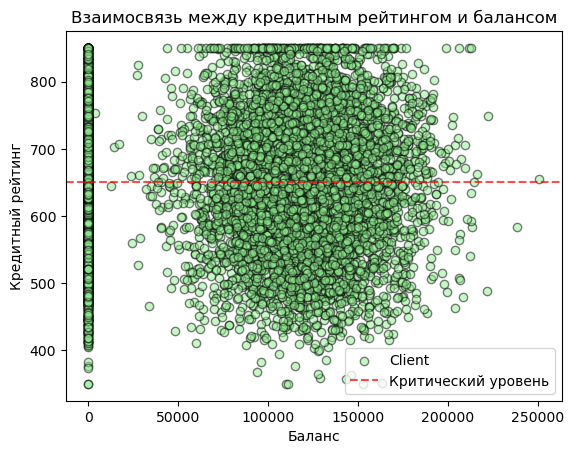

In [209]:
fig, ax = plt.subplots()

ax.scatter(
    churn_data['Balance'],
    churn_data['CreditScore'], 
    color="lightgreen", 
    edgecolor="black", 
    alpha=0.5, 
    label="Client"
)
ax.axhline(
    650, 
    color="red", 
    linestyle="--", 
    alpha=0.7, 
    label="Критический уровень")

ax.set_title("Взаимосвязь между кредитным рейтингом и балансом")
ax.set_xlabel("Баланс")
ax.set_ylabel("Кредитный рейтинг")

ax.legend()

plt.show()

**Взаимосвязь между возрастом и зарплатой.**

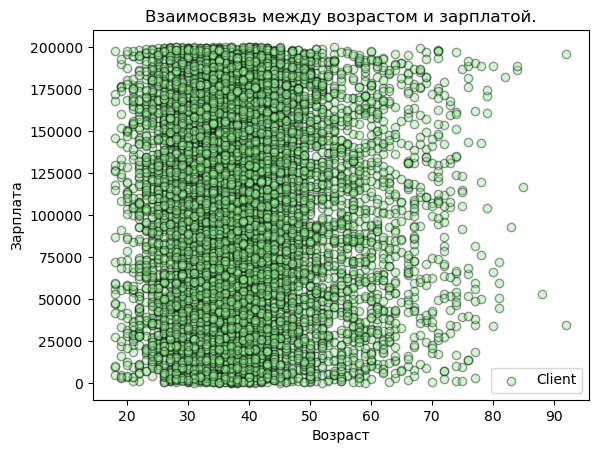

In [213]:
fig, ax = plt.subplots()

ax.scatter(
    churn_data['Age'], 
    churn_data['EstimatedSalary'], 
    color="lightgreen", 
    edgecolor="black", 
    alpha=0.4, 
    label="Client"
)

ax.set_title("Взаимосвязь между возрастом и зарплатой.")
ax.set_xlabel("Возраст")
ax.set_ylabel("Зарплата")

ax.legend()

plt.show()

**Взаимосвязь между кредитным рейтингом, балансом и статусом ушедшего.**

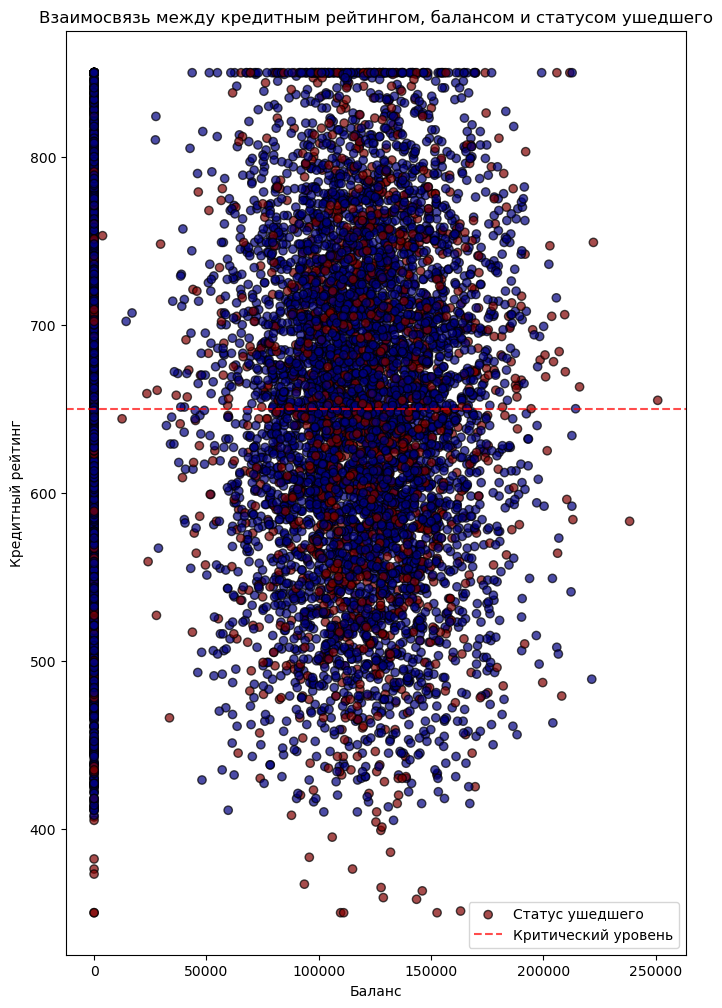

In [212]:
fig, ax = plt.subplots(figsize=(8, 12))

ax.scatter(
    churn_data['Balance'],
    churn_data['CreditScore'], 
    c=churn_data['Exited'],
    cmap="jet",
    edgecolor="black", 
    alpha=0.7, 
    label="Статус ушедшего"
)
ax.axhline(
    650, 
    color="red", 
    linestyle="--", 
    alpha=0.7, 
    label="Критический уровень")

ax.set_title("Взаимосвязь между кредитным рейтингом, балансом и статусом ушедшего")
ax.set_xlabel("Баланс")
ax.set_ylabel("Кредитный рейтинг")

ax.legend()

plt.show()

**Взаимосвязь между возрастом и кредитным рейтингом.**

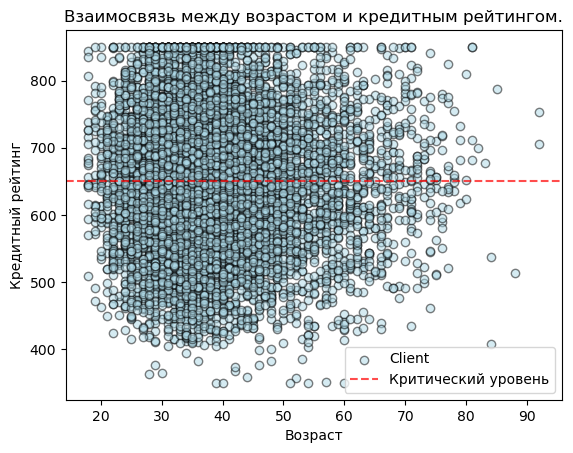

In [214]:
fig, ax = plt.subplots()

ax.scatter(
    churn_data['Age'], 
    churn_data['CreditScore'], 
    color="lightblue", 
    edgecolor="black", 
    alpha=0.5, 
    label="Client"
)
ax.axhline(
    650, 
    color="red", 
    linestyle="--", 
    alpha=0.7, 
    label="Критический уровень"
)

ax.set_title("Взаимосвязь между возрастом и кредитным рейтингом.")
ax.set_xlabel("Возраст")
ax.set_ylabel("Кредитный рейтинг")

ax.legend()

plt.show()

**Взаимосвязь между возрастом, кредитным рейтингом, балансом и зарплатой.**

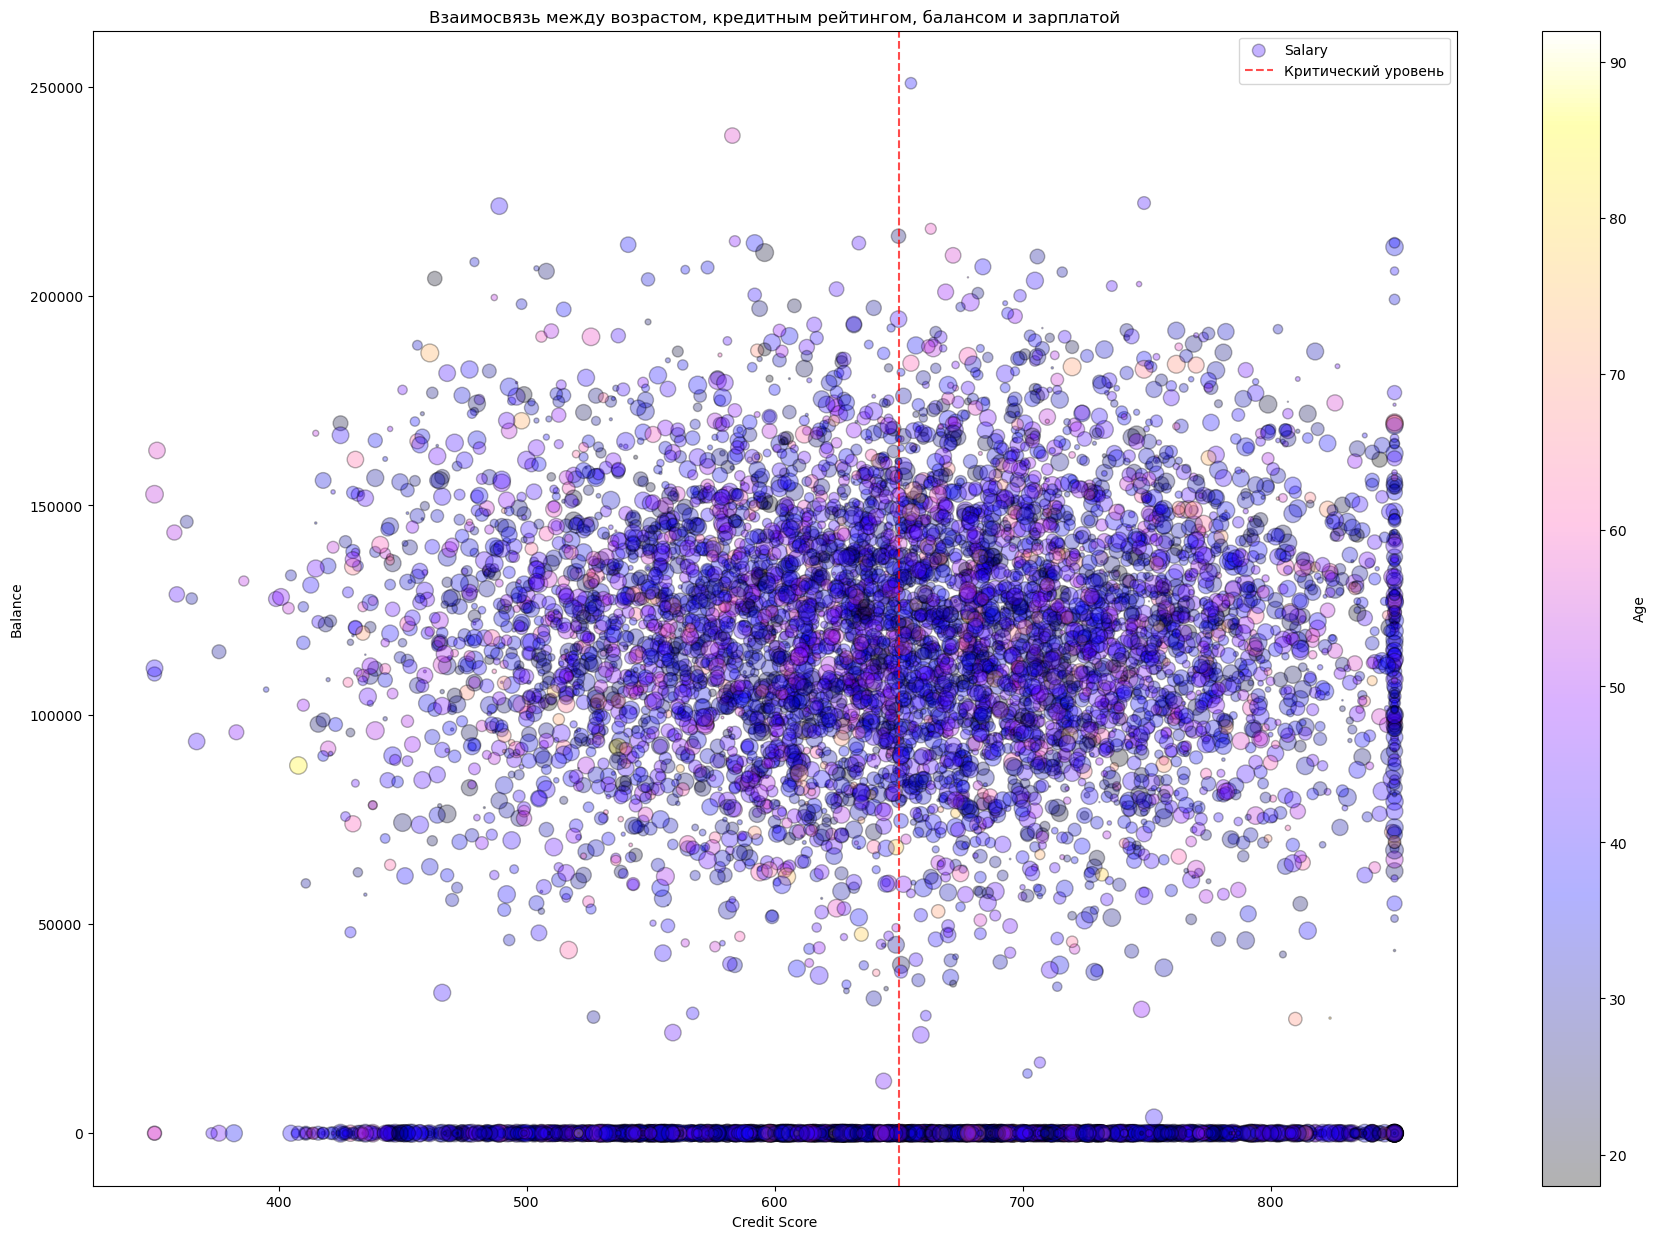

In [218]:
fig, ax = plt.subplots(figsize=(22, 15))

my_scatter = ax.scatter(
    churn_data['CreditScore'],
    churn_data['Balance'],
    s=churn_data['EstimatedSalary']/1200,
    c=churn_data['Age'],
    cmap="gnuplot2", 
    edgecolor="black",
    alpha=0.3, 
    label="Salary"
)
ax.axvline(
    650, 
    color="red", 
    linestyle="--", 
    alpha=0.7, 
    label="Критический уровень"
)

fig.colorbar(my_scatter, label="Age")

ax.set_title("Взаимосвязь между возрастом, кредитным рейтингом, балансом и зарплатой")
ax.set_xlabel("Credit Score")
ax.set_ylabel("Balance")

ax.legend()

plt.show()

## Задание 3

Сделайте интерактивную визуализацию по предложенным данным (статистика авиаперевозок).
Изобразите на ней перевозки в каждом году за каждый месяц, при этом используйте столбчатые диаграммы: один столбец — данные за один месяц в конкретном году. Одновременно на графике должны отображаться 12 столбцов для сравнения динамики за все годы в выбранный месяц. Выбор месяца организуйте, используя слайдер. 

Вы должны получить следующую визуализацию: 
1. слайдер имеет 12 позиций
2. позиции по месяцам (действительно, у нас всего 12 месяцев в каждом году)
3. для каждого месяца, в каждой позиции визуализировано 12 столбцов — измерения в указанном месяце по конкретным годам (там всего 12 лет).

In [220]:
df = pd.read_csv('hw_rt.csv')

Пример:

<a href="https://ibb.co/tPtTVvQ"><img src="https://i.ibb.co/Wpw4mMG/2023-03-23-170012.jpg" alt="2023-03-23-170012" border="0"></a>

In [221]:
# ваше прекрасное решение
df.head()

,Unnamed: 0,Дата,Кол-во пассажиров,Месяц,Год
0,0,1949-01-01,112,1,1949
1,1,1949-02-01,118,2,1949
2,2,1949-03-01,132,3,1949
3,3,1949-04-01,129,4,1949
4,4,1949-05-01,121,5,1949


In [225]:
import plotly.express as px

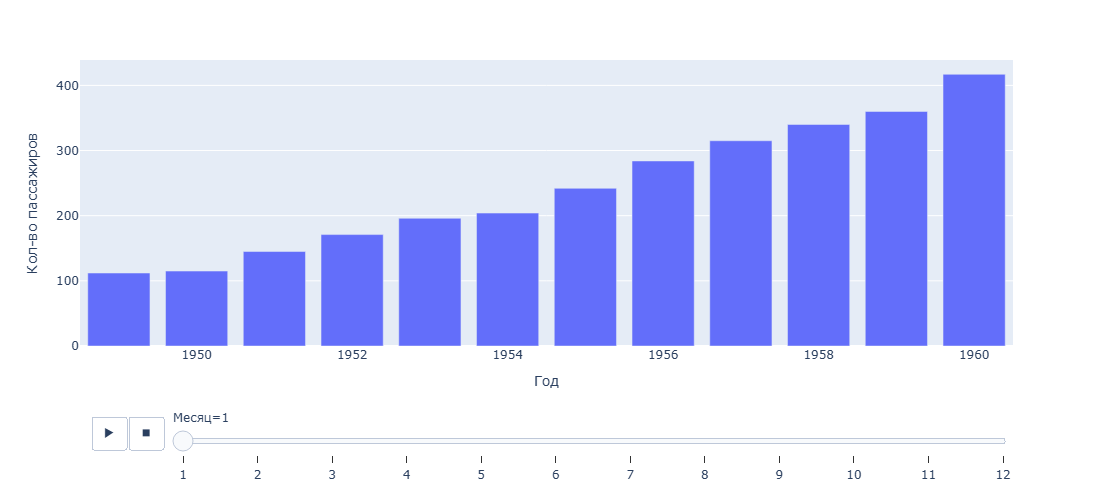

In [240]:
px.bar(
    df,
    x='Год',
    y='Кол-во пассажиров',
    animation_frame='Месяц',
    height=500    
)
